In [ ]:
import sqlite3
import re
conn = sqlite3.connect('База 1.db')  
cursor = conn.cursor()

def dictionary(entry):
    print('=' * 40)
    first_sentence = entry.split('. ')[0]  
    if '(' not in first_sentence:  
        if ' см' not in first_sentence:
            print('Тип статьи: Термин 1')
            sentences = entry.split('. ')
            sentences2 = re.split(r'(?=[а-яё])', entry)  
            term = sentences2[0].rstrip(',')
            description = sentences[0] if len(sentences) > 1 else ''
            extra_info = '. '.join(sentences[1:]) if len(sentences) > 2 else ''

            print(f'Термин: {term}')
            if description:
                print(f'Описание: {description}')
            if extra_info:
                print(f'Дополнительная информация: {extra_info}')
            latin_part = None
            cursor.execute('''INSERT INTO Term (word, latin, definition, extra_info)VALUES (?, ?, ?, ?)''', (term, latin_part, description, extra_info))
            conn.commit()
        elif ' см.' in entry:
            print('Тип статьи: Ссылка')  
            term = entry.split(', ')[0]

            sentences = entry.split('см. ')
            link = sentences[1].rstrip('.')

            print(f'Термин: {term}')
            print(f'Ссылка на статью: {link}')
            latin_part = None
            cursor.execute('''INSERT INTO Link (word, latin, link)VALUES (?, ?, ?)''', (term, latin_part, link))
            conn.commit()
    else:
        years_part = entry.split(' (')  
        if len(years_part) > 2 and 'гг.' in years_part[2].split(')')[0] and 'н.э.' not in years_part[2].split(')')[0] and 'км' not in years_part[2].split(')')[0]:
            print('Тип статьи: Археолог')

            parts = entry.split('), ')

            surname_part = parts[0].split(' (')
            surname = surname_part[0]
            surname_lat = surname_part[1]

            name_years_part = parts[1].split(' (')
            name = name_years_part[0]
            years = name_years_part[1]

            achievements_extra = parts[2].split('. ')
            achievements = achievements_extra[0]
            extra_info = '. '.join(achievements_extra[1:])

            print(f'Фамилия: {surname}')
            print(f'Фамилия (лат.): {surname_lat}')
            print(f'Имя: {name}')
            print(f'Годы жизни: {years}')
            print(f'Краткая характеристика: {achievements}')

            if extra_info:
                print(f'Доп. информация: {extra_info}')

            cursor.execute('''INSERT INTO Archaeologist (surname, surname_lat, name, years, achievements, extra_info)VALUES (?, ?, ?, ?, ?, ?)''', (surname, surname_lat, name, years, achievements, extra_info))
            conn.commit()

        elif ('(' in entry and ')' in entry and entry[entry.find(')') + 1] == '.') or (', см.' not in entry):  
            print('Тип статьи: Термин 2')

            term_part = entry.split(' (')
            term = term_part[0]
            latin_part = term_part[1].split(')')[0]
            if '(' in entry and ')' in entry and entry[entry.find(')') + 1] == '.':
                print('Term2 edit')
                prefix = f"{term} ({latin_part})"
                remaining_text = entry[len(prefix):]
                helpful = remaining_text.split('. ')
                description = helpful[0]
                extra_info = '. '.join(sentence for sentence in helpful[1:])
            else:
                print('T2 Unedit')
                parts = entry.split('), ')
                sentences = parts[1].split('. ')
                description = sentences[0]
                prefix = f"{term} ({latin_part})"
                remaining_text = entry[len(prefix):]
                helpful = remaining_text.split('. ')
                if helpful and helpful[0] == description:
                    helpful = helpful[1:]
                extra_info = '. '.join(helpful[1:])
            print(f'Термин: {term}')
            print(f'Написание термина латиницей: {latin_part}')
            if description:
                print(f'Определение: {description}')
            if extra_info:
                 print(f'Доп. информация: {extra_info}')
                
            cursor.execute('''INSERT INTO Term (word, latin, definition, extra_info)VALUES (?, ?, ?, ?)''', (term, latin_part, description, extra_info))
            conn.commit()

        elif ', см.' in entry:  
            print('Тип статьи: Ссылка')
            if '(' in entry:
                term_part = entry.split(' (')
                term = term_part[0]
                latin_part = term_part[1].split(')')[0]

                sentences = entry.split('см. ')
                link = sentences[1].rstrip('.')

                print(f'Термин: {term}')
                if latin_part:
                    print(f'Написание термина латиницей: {latin_part}')
                print(f'Ссылка на статью: {link}')
                cursor.execute('''INSERT INTO Link (word, latin, link)VALUES (?, ?, ?)''', (term, latin_part, link))
                conn.commit()

    print('\n')

with open(r"archaeological_dictionary.txt", "r", encoding="utf-8") as f:
    text = f.read()

entries = text.split('\n')

for entry in entries:
    dictionary(entry)

Тип статьи: Термин 1
Термин: АБАШЕВСКАЯ КУЛЬТУРА 
Описание: АБАШЕВСКАЯ КУЛЬТУРА бронзового века Подонья, Среднего Поволжья и Южного Урала, существует во 2–3-й четверти 2-го тысячелетия до нашей эры и предшествует срубной и андроновской культурам
Дополнительная информация: Многие ученые рассматривают А. к. как культурно-историческую общность и выделяют в ней ряд культур. Известны поселения (в т.ч. укрепленные) и множество курганных могильников (обряд — скорченные и вытянутые на спине захоронения, деревянные конструкции, кольцевые вспомогательные сооружения, особое значение имел огонь). В керамике выделяются колоколовидные и баночные формы (орнамент прочерченный); костяные дисковидные псалии с шипами свидетельствуют о появлении колесниц в степях Евразии.


Тип статьи: Термин 2
T2 Unedit
Термин: АББЕВИЛЛЬ
Написание термина латиницей: Abbeville
Определение: название наиболее ранней (доашельской) индустрии ручных рубил в Европе
Доп. информация: Эпонимная стоянка находится на 45-метровой тер

In [26]:
def crud_menu(table_name):
    def create_term():
        word = input('Слово: ')
        latin = input('Латинское написание: ')
        definition = input('Определение: ')
        extra_info = input('Доп. информация: ')
        cursor.execute(
            "INSERT INTO Term (word, latin, definition, extra_info) VALUES (?, ?, ?, ?)",
            (word, latin, definition, extra_info)
        )
        conn.commit()
        print('Термин добавлен.')

    def create_link():
        word = input('Слово: ')
        latin = input('Латинское написание: ')
        link = input('Ссылка: ')
        cursor.execute(
            "INSERT INTO Link (word, latin, link) VALUES (?, ?, ?)",
            (word, latin, link)
        )
        conn.commit()
        print('Ссылка добавлена.')

    def create_archaeologist():
        surname = input('Фамилия: ')
        surname_lat = input('Фамилия (латиницей): ')
        name = input('Имя: ')
        years = input('Годы жизни: ')
        achievements = input('Достижения: ')
        extra_info = input('Доп. информация: ')
        cursor.execute(
            "INSERT INTO Archaeologist (surname, surname_lat, name, years, achievements, extra_info) VALUES (?, ?, ?, ?, ?, ?)",
            (surname, surname_lat, name, years, achievements, extra_info)
        )
        conn.commit()
        print('Археолог добавлен.')

    def read_table():
        cursor.execute(f"SELECT * FROM {table_name}")
        rows = cursor.fetchall()
        print(f'\nСписок записей в {table_name}:')
        for row in rows:
            print(row)
        print()

    def update_table():
        rowid = input('ID статьи для обновления: ')
        if table_name == 'Term':
            word = input('Новое слово: ')
            latin = input('Новое латинское написание: ')
            definition = input('Новое определение: ')
            extra_info = input('Новая доп. информация: ')
            cursor.execute(
                "UPDATE Term SET word=?, latin=?, definition=?, extra_info=? WHERE id=?",
                (word, latin, definition, extra_info, rowid)
            )
        elif table_name == 'Link':
            word = input('Новое слово: ')
            latin = input('Новое латинское написание: ')
            link = input('Новая ссылка: ')
            cursor.execute(
                "UPDATE Link SET word=?, latin=?, link=? WHERE id=?",
                (word, latin, link, rowid)
            )
        elif table_name == 'Archaeologist':
            surname = input('Новая фамилия: ')
            surname_lat = input('Новая фамилия (лат.): ')
            name = input('Новое имя: ')
            years = input('Новые годы жизни: ')
            achievements = input('Новые достижения: ')
            extra_info = input('Новая доп. информация: ')
            cursor.execute(
                "UPDATE Archaeologist SET surname=?, surname_lat=?, name=?, years=?, achievements=?, extra_info=? WHERE id=?",
                (surname, surname_lat, name, years, achievements, extra_info, rowid)
            )
        conn.commit()
        print('Статья обновлена.')

    def delete_table():
        rowid = input('ID статьи для удаления: ')
        cursor.execute(f"DELETE FROM {table_name} WHERE id=?", (rowid,))
        conn.commit()
        print('Статья удалена.')

    def show_menu():
        while True:
            print('\nМеню работы с таблицей:', table_name)
            print('1 - Добавить статью')
            print('2 - Показать все статьи')
            print('3 - Обновить статью')
            print('4 - Удалить статью')
            print('5 - Вернуться назад\n')
            choice = input('Выбери действие (1-5): ')
            if choice == '1':
                if table_name == 'Term':
                    create_term()
                elif table_name == 'Link':
                    create_link()
                elif table_name == 'Archaeologist':
                    create_archaeologist()
            elif choice == '2':
                read_table()
            elif choice == '3':
                update_table()
            elif choice == '4':
                delete_table()
            elif choice == '5':
                break
            else:
                print('Ошибка. Введите верное значение')
    show_menu()

def main_menu():
    while True:
        print('\n' + '='*39)
        print(' Редактирование словарных статей. Меню ')
        print('='*39)
        print('1 - Термины (Term)')
        print('2 - Ссылки (Link)')
        print('3 - Археологи (Archaeologist)')
        print('4 - Выход\n')
        choice = input('Выберите тип статьи (1-4): ')
        if choice == '1':
            crud_menu('Term')
        elif choice == '2':
            crud_menu('Link')
        elif choice == '3':
            crud_menu('Archaeologist')
        elif choice == '4':
            print('Редактирование завершено')
            break
        else:
            print('Ошибка. Введите верное значение')

main_menu()


 Редактирование словарных статей. Меню 
1 - Термины (Term)
2 - Ссылки (Link)
3 - Археологи (Archaeologist)
4 - Выход



Выберите тип статьи (1-4):  4


Редактирование завершено


In [ ]:
import sqlite3

def export_dictionary_sorted(db_path, output_file):
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()

    articles = []

    cursor.execute("SELECT DISTINCT word, latin, definition, extra_info FROM Term")
    terms = cursor.fetchall()
    for word, latin, definition, extra_info in terms:
        word_to_display = word if latin else ''
        latin_part = f" ({latin}), " if latin else ''
        extra = f" {extra_info}" if extra_info else ''
        article_text = f"{word_to_display}{latin_part}{definition}{extra}\n"
        articles.append((word, article_text))
        
    cursor.execute("SELECT DISTINCT word, latin, link FROM Link")
    links = cursor.fetchall()
    for word, latin, link in links:
        latin_part = f" ({latin})" if latin else ''
        article_text = f"{word}{latin_part}, см. {link}.\n"
        articles.append((word, article_text))

    cursor.execute("SELECT DISTINCT surname, surname_lat, name, years, achievements, extra_info FROM Archaeologist")
    archs = cursor.fetchall()
    for surname, surname_lat, name, years, achievements, extra_info in archs:
        surname_lat_part = f" ({surname_lat})" if surname_lat else ''
        extra_part = f" {extra_info}" if extra_info else ''
        article_text = f"{surname}{surname_lat_part} {name}, {years} {achievements}.{extra_part}\n"
        articles.append((surname, article_text))

    articles.sort()

    with open(output_file, 'w', encoding='utf-8') as f:
        for _, article_text in articles:
            f.write(article_text)

    conn.close()
    print(f'Экспорт всех таблиц завершён. Файл сохранён: {output_file}')

export_dictionary_sorted('База 1.db', 'archaeological_dictionary_out.txt')

Экспорт всех таблиц завершён. Файл сохранён: Археологический_словарь_out.txt


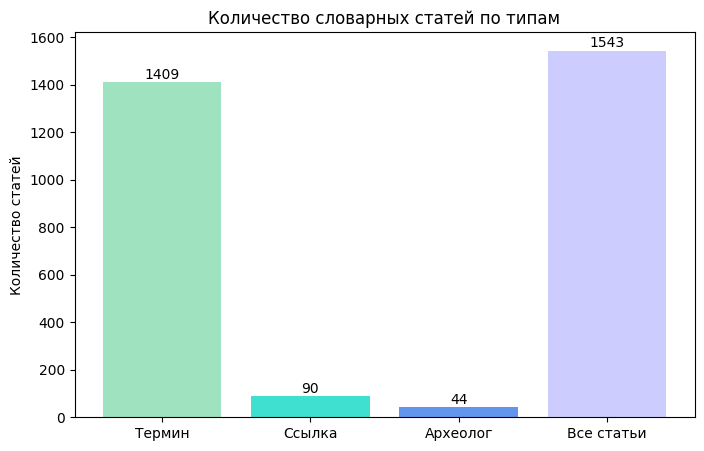

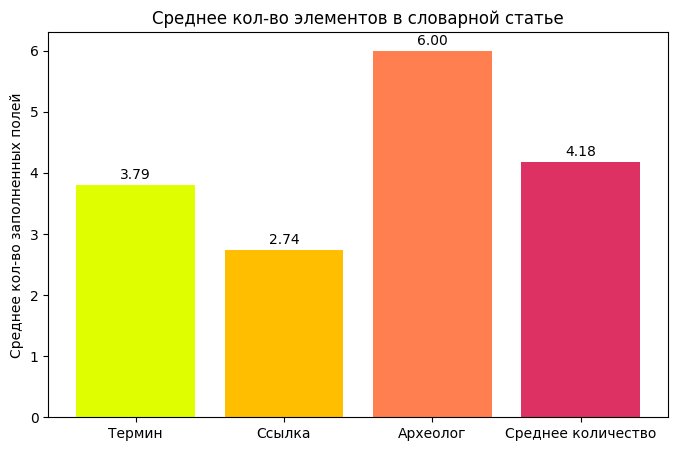

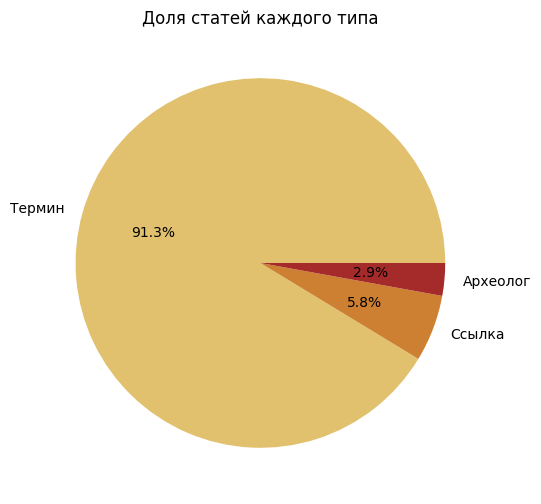

In [63]:
import sqlite3
import matplotlib.pyplot as plt

conn = sqlite3.connect('База 1.db')
cursor = conn.cursor()

def count_all (table, columns):
    expr_sum = " + ".join([f"(CASE WHEN {col} IS NOT NULL AND {col} != '' THEN 1 ELSE 0 END)" for col in columns])
    query = f"SELECT DISTINCT COUNT(*), SUM({expr_sum}) FROM {table}"
    cursor.execute(query)
    count, fin_sum = cursor.fetchone()
    avg = fin_sum / count
    return count, avg

term_count, avg_term = count_all ('Term', ['word', 'latin', 'definition', 'extra_info'])
link_count, avg_link = count_all ('Link', ['word', 'latin', 'link'])
arch_count, avg_arch = count_all ('Archaeologist', ['surname', 'surname_lat', 'name', 'years', 'achievements', 'extra_info'])

labels = ['Термин', 'Ссылка', 'Археолог','Все статьи']
counts = [term_count, link_count, arch_count, (term_count+link_count+arch_count)]

plt.figure(figsize=(8,5)) 
bars = plt.bar(labels, counts, color=['#9FE2BF', '#40E0D0', '#6495ED','#CCCCFF'])
plt.title('Количество словарных статей по типам')
plt.ylabel('Количество статей')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, int(yval), ha='center', va='bottom')

plt.show()

labels_avg = ['Термин', 'Ссылка', 'Археолог', 'Среднее количество']
averages = [avg_term, avg_link, avg_arch, (avg_term + avg_link + avg_arch)/3]

plt.figure(figsize=(8,5))
bars = plt.bar(labels_avg, averages, color=['#DFFF00', '#FFBF00', '#FF7F50', '#DE3163'])
plt.title('Среднее кол-во элементов в словарной статье')
plt.ylabel('Среднее кол-во заполненных полей')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f"{yval:.2f}", ha='center', va='bottom')
plt.show()

labels2 = ['Термин', 'Ссылка', 'Археолог']
counts2 = [term_count, link_count, arch_count]

plt.figure(figsize=(6,6))
plt.pie(counts2, labels=labels2, autopct='%1.1f%%', colors=['#E1C16E', '#CD7F32', '#A52A2A'])
plt.title('Доля статей каждого типа')
plt.show()

conn.close()
